# 03 - Modelado predictivo y explicabilidad

Proyecto: Radiografía de Steam (EIN092B Visualización, 2026-II). Avance 3.

**Pregunta predictiva.** Con información disponible el día del lanzamiento, ¿quedará el juego entre el 20 % con más reseñas de su año?

Flujo: definición de y, construcción de X sin fuga de información, partición temporal, validación cruzada hacia adelante, comparación de dos modelos (regresión logística y LightGBM), elección de umbral, evaluación en prueba y explicabilidad global y local con SHAP. Las funciones están en `src/modelado.py`.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

from src import config, data_loading, modelado as m

datos = data_loading.limpiar(data_loading.cargar_crudo(config.RUTA_DATOS_RAW))
print('Juegos 2014 a 2024:', len(datos))

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Juegos 2014 a 2024: 95595


## 1. Variable objetivo

Un umbral fijo de reseñas (por ejemplo, 100) mezcla calidad de publicación con tiempo de exposición: los juegos antiguos acumulan más reseñas. Por eso se marca como destacado al 20 % con más reseñas **dentro de su año de lanzamiento**.

In [2]:
y = m.crear_objetivo(datos)
comparacion = pd.DataFrame({
    'umbral_reseñas': m.umbrales_por_anio(datos).round(0),
    'prevalencia_objetivo': y.groupby(datos['anio']).mean().round(3),
    'prevalencia_umbral_fijo_100': (datos['total_resenas'] >= 100).groupby(datos['anio']).mean().round(3),
})
comparacion

,umbral_reseñas,prevalencia_objetivo,prevalencia_umbral_fijo_100
anio,,,
2014,1571.0,0.200,0.766
2015,879.0,0.200,0.597
2016,487.0,0.201,0.471
2017,240.0,0.200,0.325
2018,160.0,0.201,0.255
2019,152.0,0.200,0.244
2020,131.0,0.200,0.227
2021,68.0,0.201,0.169
2022,49.0,0.200,0.142


## 2. Variables predictoras (X)

Solo información que el juego tiene al publicarse. Las variables excluidas y su motivo están en `m.EXCLUIDAS`.

In [3]:
pd.Series(m.EXCLUIDAS, name='motivo de exclusión').to_frame()

,motivo de exclusión
"Reseñas, recomendaciones, propietarios, pico de jugadores",definen o reflejan el objetivo
"Tiempo de juego, Metacritic, puntaje de usuarios",se miden después del lanzamiento
DLC y Steam Workshop,suelen agregarse cuando el juego ya tuvo éxito
Cromos de Steam (Trading Cards),Valve los habilita según las ventas
Etiquetas (Tags),las asignan los jugadores
Descuento actual,"es una condición de hoy, no del lanzamiento"


In [4]:
entrenamiento, prueba = m.particion_temporal(datos)
X_ent, generos = m.construir_variables(datos[entrenamiento])
X_pru, _ = m.construir_variables(datos[prueba], generos)
y_ent, y_pru = y[entrenamiento].values, y[prueba].values
anios_ent = datos.loc[entrenamiento, 'anio'].values
print('Entrenamiento (2014 a 2022):', X_ent.shape, '| prevalencia', round(y_ent.mean(), 3))
print('Prueba (2023 y 2024):', X_pru.shape, '| prevalencia', round(y_pru.mean(), 3))
print('Accuracy de predecir siempre 0 en prueba:', round(1 - y_pru.mean(), 3))

Entrenamiento (2014 a 2022): (60964, 50) | prevalencia 0.2
Prueba (2023 y 2024): (34631, 50) | prevalencia 0.202
Accuracy de predecir siempre 0 en prueba: 0.798


## 3. Validación cruzada hacia adelante y umbral

Cada pliegue entrena con los años anteriores y valida con el siguiente (2019 a 2022). Con las predicciones de validación se elige el umbral que maximiza F1, y ese umbral se aplica sin cambios al conjunto de prueba.

In [5]:
Xl_ent, Xl_pru = m.transformar_para_lineal(X_ent), m.transformar_para_lineal(X_pru)
fabricas = {
    'Regresión logística': (lambda: m.modelo_logistico(C=1.0), Xl_ent, Xl_pru),
    'LightGBM': (lambda: m.modelo_lightgbm(num_leaves=31, n_estimators=400), X_ent, X_pru),
}
resultados, prob_prueba, modelos = {}, {}, {}
for nombre, (fabrica, Xe, Xp) in fabricas.items():
    oof_p, oof_y, auc_pliegues = [], [], []
    for i_e, i_v in m.pliegues_hacia_adelante(anios_ent):
        modelo = fabrica().fit(Xe.iloc[i_e], y_ent[i_e])
        p = modelo.predict_proba(Xe.iloc[i_v])[:, 1]
        oof_p.append(p); oof_y.append(y_ent[i_v])
        auc_pliegues.append(roc_auc_score(y_ent[i_v], p))
    oof_p, oof_y = np.concatenate(oof_p), np.concatenate(oof_y)
    umbral = m.umbral_optimo_f1(oof_y, oof_p)
    modelo = fabrica().fit(Xe, y_ent)
    modelos[nombre] = modelo
    prob_prueba[nombre] = modelo.predict_proba(Xp)[:, 1]
    resultados[nombre] = {
        'umbral': round(umbral, 2),
        'auc_cv_pliegues': np.round(auc_pliegues, 3).tolist(),
        'auc_entrenamiento': roc_auc_score(y_ent, modelo.predict_proba(Xe)[:, 1]),
        'auc_cv': roc_auc_score(oof_y, oof_p),
        **{k + '_prueba': v for k, v in m.metricas(y_pru, prob_prueba[nombre], umbral).items()},
    }
pd.DataFrame(resultados).T

,umbral,auc_cv_pliegues,auc_entrenamiento,auc_cv,accuracy_prueba,precision_prueba,recall_prueba,f1_prueba,roc_auc_prueba,ap_prueba
Regresión logística,0.29,"[0.798, 0.819, 0.802, 0.801]",0.812124,0.804246,0.789379,0.482336,0.608048,0.537945,0.805787,0.554726
LightGBM,0.31,"[0.825, 0.845, 0.836, 0.829]",0.880406,0.833677,0.809362,0.523201,0.615208,0.565486,0.830076,0.621506


## 4. Diferencia entre modelos (bootstrap pareado)

Se remuestrea el conjunto de prueba 1.000 veces y se calcula la diferencia de ROC-AUC y AP entre LightGBM y la regresión logística en cada muestra.

In [6]:
rng = np.random.default_rng(m.SEMILLA)
pl, pg = prob_prueba['Regresión logística'], prob_prueba['LightGBM']
dif_auc, dif_ap = [], []
for _ in range(1000):
    i = rng.integers(0, len(y_pru), len(y_pru))
    dif_auc.append(roc_auc_score(y_pru[i], pg[i]) - roc_auc_score(y_pru[i], pl[i]))
    dif_ap.append(average_precision_score(y_pru[i], pg[i]) - average_precision_score(y_pru[i], pl[i]))
print('Diferencia AUC, IC 95 %:', np.round(np.percentile(dif_auc, [2.5, 50, 97.5]), 4))
print('Diferencia AP,  IC 95 %:', np.round(np.percentile(dif_ap, [2.5, 50, 97.5]), 4))

Diferencia AUC, IC 95 %: [0.0215 0.0243 0.0269]
Diferencia AP,  IC 95 %: [0.0604 0.0666 0.073 ]


## 5. Curvas ROC y Precision-Recall

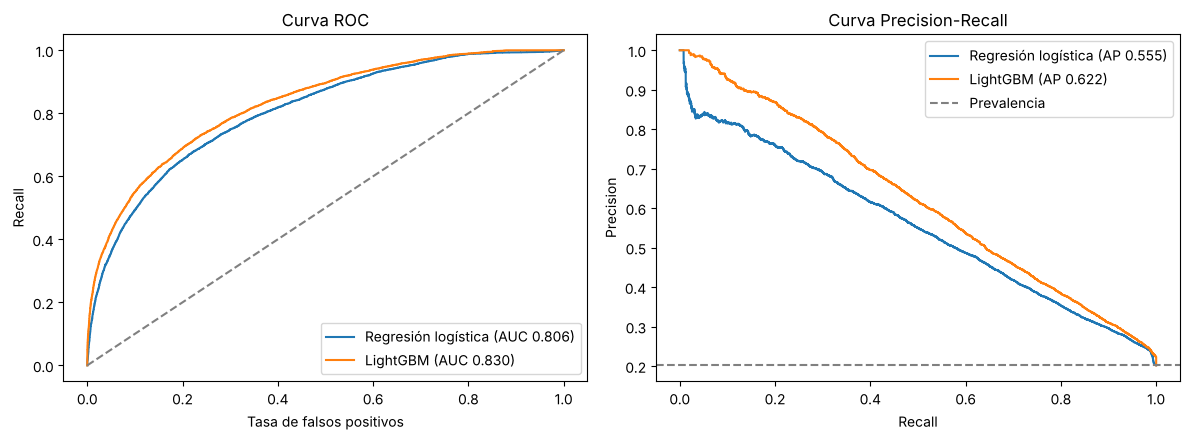

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for nombre, p in prob_prueba.items():
    fpr, tpr, _ = roc_curve(y_pru, p)
    pre, rec, _ = precision_recall_curve(y_pru, p)
    a1.plot(fpr, tpr, label=f"{nombre} (AUC {roc_auc_score(y_pru, p):.3f})")
    a2.plot(rec, pre, label=f"{nombre} (AP {average_precision_score(y_pru, p):.3f})")
a1.plot([0, 1], [0, 1], '--', color='grey'); a2.axhline(y_pru.mean(), ls='--', color='grey', label='Prevalencia')
a1.set(xlabel='Tasa de falsos positivos', ylabel='Recall', title='Curva ROC')
a2.set(xlabel='Recall', ylabel='Precision', title='Curva Precision-Recall')
a1.legend(); a2.legend(); plt.tight_layout()

In [8]:
for nombre, p in prob_prueba.items():
    cm = confusion_matrix(y_pru, (p >= resultados[nombre]['umbral']).astype(int))
    print(nombre, '\n', pd.DataFrame(cm, index=['real 0', 'real 1'], columns=['pred 0', 'pred 1']), '\n')

Regresión logística 
         pred 0  pred 1
real 0   23091    4557
real 1    2737    4246 

LightGBM 
         pred 0  pred 1
real 0   23733    3915
real 1    2687    4296 



## 6. Explicabilidad global (SHAP)

Se calculan valores SHAP de LightGBM sobre una muestra de 3.000 juegos de prueba.

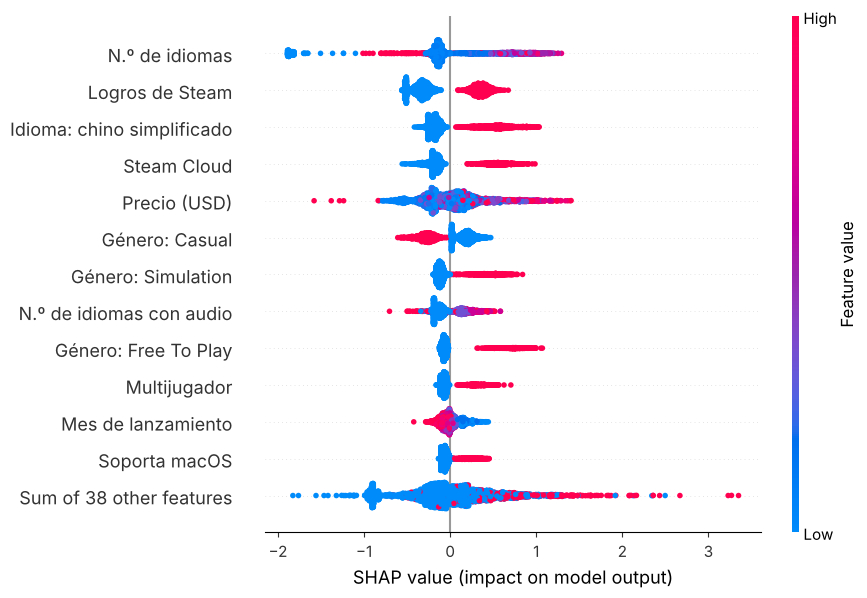

In [9]:
X_pru_r = X_pru.reset_index(drop=True)
nombres = [m.etiqueta(c) for c in X_pru_r.columns]
explicador = shap.TreeExplainer(modelos['LightGBM'])
muestra = np.random.default_rng(m.SEMILLA).choice(len(X_pru_r), 3000, replace=False)
exp = explicador(X_pru_r.iloc[muestra])
exp.feature_names = nombres
shap.plots.beeswarm(exp, max_display=13)

In [10]:
pd.Series(np.abs(exp.values).mean(0), index=nombres).sort_values(ascending=False).head(15).round(3)

N.º de idiomas                0.482
Logros de Steam               0.353
Idioma: chino simplificado    0.293
Steam Cloud                   0.274
Precio (USD)                  0.261
Género: Casual                0.219
Género: Simulation            0.181
N.º de idiomas con audio      0.155
Género: Free To Play          0.148
Multijugador                  0.111
Mes de lanzamiento            0.084
Soporta macOS                 0.083
Idioma: chino tradicional     0.079
Género: Adventure             0.078
N.º de géneros                0.076
dtype: float64

## 7. Explicabilidad local

Tres casos: un acierto (Black Myth: Wukong), un falso negativo (Gorilla Tag) y un falso positivo causado por una ficha duplicada (Call of Duty: Modern Warfare III, AppID 3595270, cuya otra ficha, 2519060, concentra las reseñas).

Black Myth: Wukong | real: 1 | reseñas: 1150098 | probabilidad: 0.993


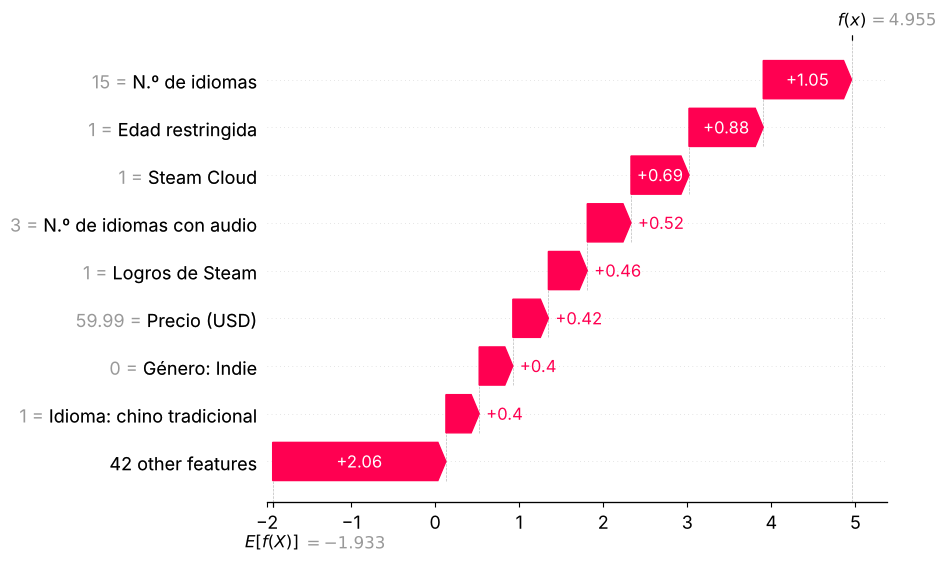

Gorilla Tag | real: 1 | reseñas: 71163 | probabilidad: 0.05


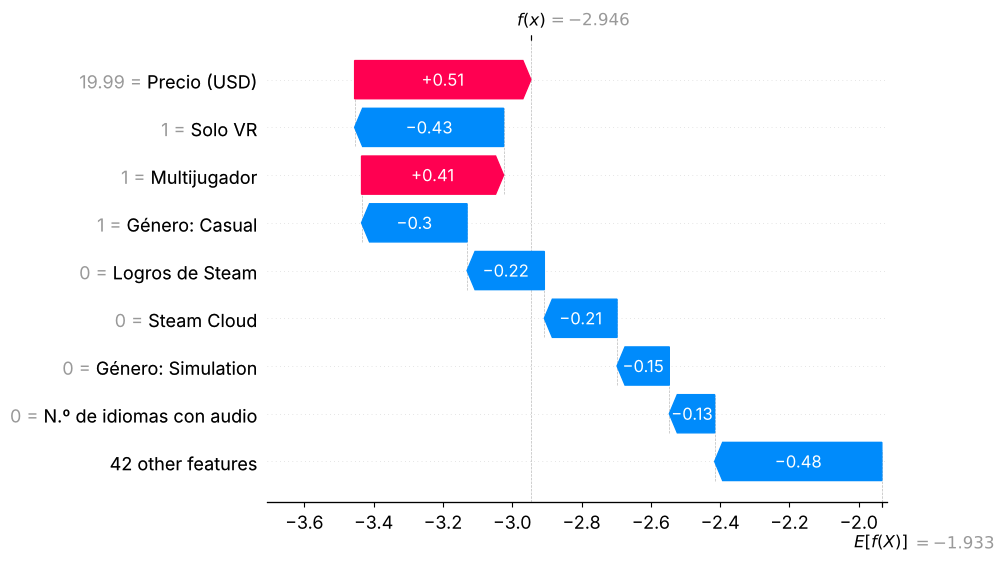

Call of Duty®: Modern Warfare® III | real: 0 | reseñas: 0 | probabilidad: 0.974


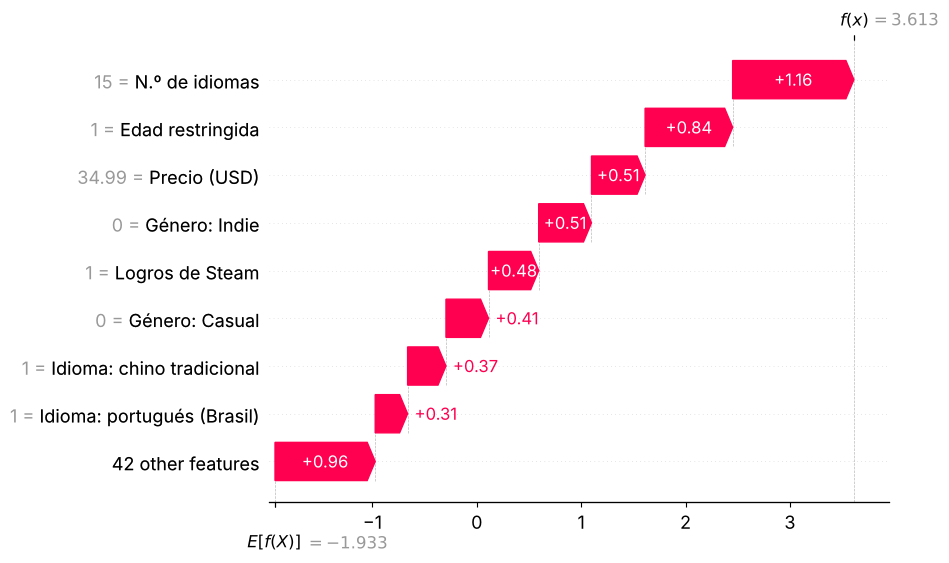

In [11]:
info_pru = datos[prueba].reset_index(drop=True)
for app_id in [2358720, 1533390, 3595270]:
    i = int(info_pru.index[info_pru['app_id'] == app_id][0])
    e = explicador(X_pru_r.iloc[[i]]); e.feature_names = nombres
    print(info_pru.loc[i, 'nombre'], '| real:', y_pru[i], '| reseñas:', int(info_pru.loc[i, 'total_resenas']),
          '| probabilidad:', round(float(pg[i]), 3))
    shap.plots.waterfall(e[0], max_display=9)

In [12]:
# Falsos positivos de alta confianza con 0 resenas (fichas duplicadas o secundarias)
u = resultados['LightGBM']['umbral']
fp_alta = (pg > 0.8) & (y_pru == 0)
print('Falsos positivos con probabilidad > 0,8:', int(fp_alta.sum()))
print('De ellos, con 0 reseñas:', int((fp_alta & (info_pru['total_resenas'].values == 0)).sum()))

Falsos positivos con probabilidad > 0,8: 249
De ellos, con 0 reseñas: 116


## 8. Conclusiones

1. LightGBM supera a la regresión logística en todos los pliegues y en prueba (ROC-AUC 0,830 frente a 0,806; AP 0,622 frente a 0,555), con una diferencia cuyo intervalo de confianza no incluye el cero.
2. Las variables más influyentes son el número de idiomas (con caída cuando se marcan en bloque), los logros de Steam, el chino simplificado, Steam Cloud y el precio, cuya relación no es lineal. Son asociaciones, no efectos causales.
3. La principal limitación es el ruido en la variable objetivo: fichas duplicadas con 0 reseñas aparecen como falsos positivos. El siguiente paso es unificarlas.